In [ ]:
!pip install jupyter_black

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.4/268.4 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 78.0 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline
%load_ext jupyter_black

In [ ]:
# download the names.txt file from github
!wget https://raw.githubusercontent.com/karpathy/makemore/master/names.txt

--2026-09-17 06:17:10--  https://raw.githubusercontent.com/karpathy/makemore/master/names.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 228145 (223K) [text/plain]
Saving to: ‘names.txt.1’

names.txt.1         100%[===================>] 222.80K  --.-KB/s    in 0.04s   

2026-09-17 06:17:10 (4.94 MB/s) - ‘names.txt.1’ saved [228145/228145]



In [ ]:
# read in all the words
words = open("names.txt", "r").read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [ ]:
len(words)

32033

In [ ]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set("".join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi["."] = 0
itos = {i: s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [ ]:
# build the dataset
block_size = (
    3  # context length: how many characters do we take to predict the next one?
)


def build_dataset(words):
    X, Y = [], []

    for w in words:
        context = [0] * block_size
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]  # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


import random

random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])  # 80%
Xdev, Ydev = build_dataset(words[n1:n2])  # 10%
Xte, Yte = build_dataset(words[n2:])  # 10%

torch.Size([182580, 3]) torch.Size([182580])
torch.Size([22767, 3]) torch.Size([22767])
torch.Size([22799, 3]) torch.Size([22799])


In [ ]:
n_embd = 10  # the dimensionality of the character embedding vectors
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

kaiming_gain = (5 / 3) / ((n_embd * block_size) ** 0.5)
g = torch.Generator().manual_seed(2147483647)  # for reproducibility
C = torch.randn((vocab_size, n_embd), generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * kaiming_gain  # * 0.2
b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

# imp batch norm
bngain = torch.ones((1, n_hidden))  # ones
bnbais = torch.zeros((1, n_hidden))  # zeros
bnmean_running = torch.zeros((1, n_hidden))  # no gradients
bnstd_running = torch.ones((1, n_hidden))  # no gradients

parameters = [C, W1, b1, W2, b2, bngain, bnbais]
print(sum(p.nelement() for p in parameters))  # number of parameters in total
for p in parameters:
    p.requires_grad = True

12297


In [ ]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]  # batch X,Y

    # forward pass
    emb = C[Xb]  # embed the characters into vectors
    embcat = emb.view(emb.shape[0], -1)  # concatenate the vectors
    # Linear layer
    hpreact = embcat @ W1 # + b1  # hidden layer pre-activation, b1 is getting cancelled by batch_norm

    # batch normalize
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    hpreact = bngain * ((hpreact - bnmeani) / bnstdi) + bnbais

    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

    # Non-linearity
    h = torch.tanh(hpreact)  # hidden layer
    logits = h @ W2 + b2  # output layer
    loss = F.cross_entropy(logits, Yb)  # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01  # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())

      0/ 200000: 3.3014
  10000/ 200000: 2.4789
  20000/ 200000: 2.3364
  30000/ 200000: 2.1072
  40000/ 200000: 2.0523
  50000/ 200000: 2.4329
  60000/ 200000: 2.2905
  70000/ 200000: 2.0826
  80000/ 200000: 2.0123
  90000/ 200000: 2.0183
 100000/ 200000: 2.4473
 110000/ 200000: 2.0486
 120000/ 200000: 2.1925
 130000/ 200000: 2.3583
 140000/ 200000: 2.2693
 150000/ 200000: 2.3672
 160000/ 200000: 2.0888
 170000/ 200000: 2.0872
 180000/ 200000: 2.4111
 190000/ 200000: 1.8808


In [ ]:
# b1.grad.mean() # tensor(5.3260e-11) almost zerograd cause of batch norm

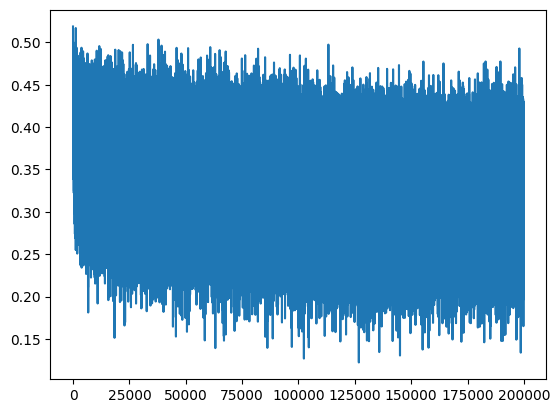

In [ ]:
plt.plot(lossi)

In [ ]:
# calibrate the batch norm at the end of training

with torch.no_grad():
    # pass the training set through
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1  # + b1
    # measure the mean/std over the entire training set
    bnmean = hpreact.mean(0, keepdim=True)
    bnstd = hpreact.std(0, keepdim=True)

In [ ]:
bnmean[:, 10:15], bnmean_running[:, 10:15]

(tensor([[-2.6019, -2.1315, -0.5544, -0.8258, -0.5959]]),
 tensor([[-2.5673, -2.1399, -0.5380, -0.8096, -0.5738]]))

In [ ]:
@torch.no_grad()  # this decorator disables gradient tracking
def split_loss(split):
    x, y = {
        "train": (Xtr, Ytr),
        "val": (Xdev, Ydev),
        "test": (Xte, Yte),
    }[split]
    emb = C[x]  # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1)  # concat into (N, block_size * n_embd)
    hpreact = embcat @ W1 + b1

    hpreact = bngain * ((hpreact - bnmean_running) / bnstd_running) + bnbais

    h = torch.tanh(hpreact)  # (N, n_hidden)
    logits = h @ W2 + b2  # (N, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())


split_loss("train")
split_loss("val")

train 2.065549850463867
val 2.111138343811035


In [ ]:
# with normal kaiming init
# train 2.038853168487549
# val 2.108774185180664

### Avoid using Batchnorm cause its essentially taking batches and before the output was function of weights and data but now its also including mini batches mean and std which gives a kind of regularizing effect but can be bad cause of its dependecy on minibatches as well.

In [ ]:
import torch
import matplotlib.pyplot as plt
import torch.nn as nn
import time
import torch.nn.functional as F

from sklearn.datasets import load_breast_cancer


class Linear:
    def __init__(self, in_features, out_features, bias=True):
        self.w = (
            # torch.randn((in_features, out_features))
            # * in_features**0.5
            # * (5 / 3)
            # / (in_features**0.5)
            torch.randn((in_features, out_features))
            * 0.01
        ).requires_grad_(True)
        self.b = torch.zeros((out_features), requires_grad=True) if bias else None

    def __call__(self, x):
        out = x @ self.w
        if self.b is not None:
            out = out + self.b
        return out

    def parameters(self):
        if self.b is None:
            return [self.w]
        return [self.w, self.b]


class Tanh:
    def __call__(self, x):
        out = torch.tanh(x)
        return out

    def parameters(self):
        return []


class BatchNorm1d:
    def __init__(self):
        # self
        pass

    def __call__(self, x):
        out = x
        return out

    def parameters(self):
        return []


if __name__ == "__main__":
    X_df, y_df = load_breast_cancer(return_X_y=True, as_frame=True)
    X = torch.tensor(X_df.values, dtype=torch.float32)
    y = torch.tensor(y_df.values, dtype=torch.float32).unsqueeze(1)
    _, features = X.shape

    layers = [Linear(features, 64), Tanh(), Linear(64, 16), Tanh(), Linear(16, 1)]
    parameters = []
    for layer in layers:
        parameters.extend(layer.parameters())
    print("params len = ", len(parameters))

    lr = 0.01
    lossi = []
    epochs = 200000
    with torch.no_grad():
        for layer in layers:
            if isinstance(layer, Linear):
                layer.w *= 1.0
                # layer.w *= 5 / 3

    for epoch in range(epochs):
        out = X
        for layer in layers:
            out = layer(out)
            # zero grad
            for param in layer.parameters():
                param.grad = None

        loss = F.binary_cross_entropy_with_logits(out, y)
        loss.backward()
        lossi.append(loss.detach().cpu().numpy())

        # step
        with torch.no_grad():
            for layer in layers:
                for param in layer.parameters():
                    param.data -= lr * param.grad

        if epoch % 50 == 0:
            # print(out[:2])
            print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

    # print(out)
    stepi = [i for i in range(epochs)]
    plt.plot(stepi, lossi)
    plt.show()
